In [26]:
import pandas as pd
import webbrowser
import matplotlib.pyplot as plt
import seaborn as sns


# Complete dataset for XGboost model

This is the complete dataset used for predicting 2023 rent prices. It has merged property data with distance to school, uni, hospitals, train station, city centre, offence count, average family size, resident population, average household income in the area etc.



In [27]:
xgboost_data_2023 = pd.read_csv("../data/curated/data_XGBoost_before_onehotencode.csv")
xgboost_data_2023.head()

,property type,beds,baths,parking,weekly rent amount,distance primary school,distance secondary school,is closest school good,distance university campus,distance to closest hospital,...,closest_city_centre,coastal,closest_cc_dist,dist_to_melb,predicted median equivalised total household income (weekly) ($) 2023,predicted median weekly household rental payment ($) 2023,predicted average family size (no. of persons) 2023,predicted employment ratio 2023,predicted estimated resident population (no.) 2023,predicted total dwellings (no.) 2023
0,House,1,2,6,120,0.586504,2.491226,True,7.430317,2.104719,...,Melbourne,False,11.566742,12.618789,1567.422222,487.077778,3.030000,0.952619,42748.566667,18091.000000
1,House,9,2,2,130,1.372612,2.438191,False,0.675843,6.688022,...,Geelong,False,7.459818,71.172437,1172.308333,403.983333,3.019167,0.956643,76343.466667,31411.666667
2,House,1,1,0,140,4.858273,3.301447,True,47.278807,10.766412,...,Cranbourne,False,37.174742,58.248165,985.433333,429.133333,2.700000,0.967222,13759.066667,9143.000000
3,House,1,2,6,140,1.114181,1.998214,False,1.502495,6.057051,...,Geelong,False,7.459818,71.172437,1172.308333,403.983333,3.019167,0.956643,76343.466667,31411.666667
4,House,1,4,3,150,0.215009,1.989564,False,1.862509,5.472987,...,Geelong,False,7.459818,71.172437,1172.308333,403.983333,3.019167,0.956643,76343.466667,31411.666667


Features used for xgboost model for predicting 2023 rent prices:

In [28]:
list(xgboost_data_2023.columns)

['property type',
 'beds',
 'baths',
 'parking',
 'weekly rent amount',
 'distance primary school',
 'distance secondary school',
 'is closest school good',
 'distance university campus',
 'distance to closest hospital',
 'offence count 2023',
 'distance train station',
 'city_centre',
 'closest_city_centre',
 'coastal',
 'closest_cc_dist',
 'dist_to_melb',
 'predicted median equivalised total household income (weekly) ($) 2023',
 'predicted median weekly household rental payment ($) 2023',
 'predicted average family size (no. of persons) 2023',
 'predicted employment ratio 2023',
 'predicted estimated resident population (no.) 2023',
 'predicted total dwellings (no.) 2023']

# XGBoost performance 

Split the dataset into 80-20 train and test split. Model was trained thorugh gridsearch on training set and tested on test set

Bar plot of the average error in prediction for each rent price. Error is defined as abs(true price - predicted price)

Text(0.5, 1.0, 'True Rent Price vs Averate Prediction Error Bar Plot')

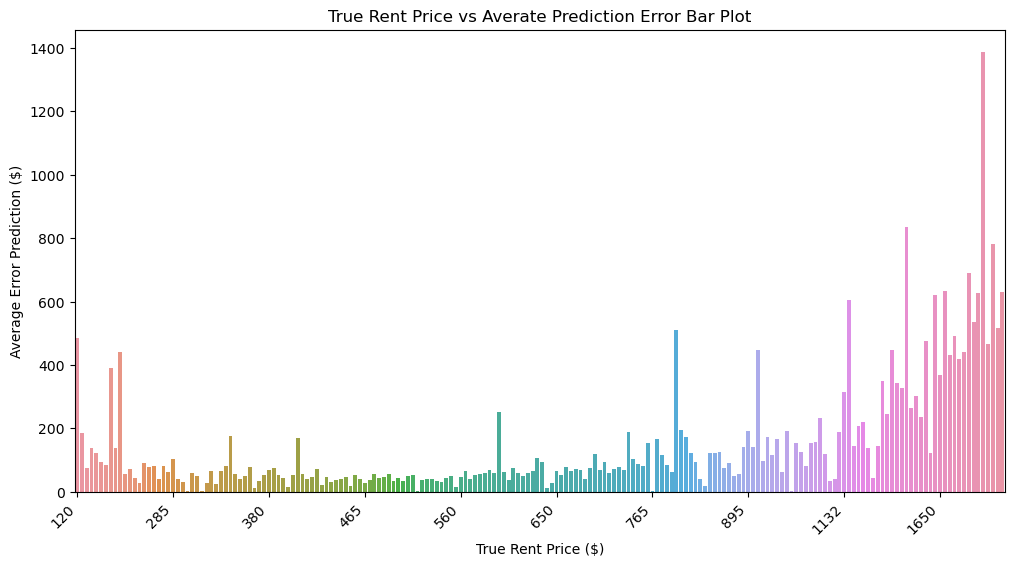

In [29]:
# read in file with average error per rent price
average_error_rent_price = pd.read_csv("../data/curated/average_error_rent_price.csv")

# Bar plot of average errors for rental price
fig, ax = plt.subplots(figsize=(12, 6))
sns.barplot(x="true rent price", y="error", data=average_error_rent_price, ax=ax)
tick_interval = 20  # Show every 20th label
x_values = list(average_error_rent_price["true rent price"])
visible_indices = range(0, len(x_values), tick_interval) 
visible_ticks = [x_values[i] for i in visible_indices]
ax.set_xticks(visible_indices)
ax.set_xticklabels(visible_ticks, rotation=45, ha='right')  # Rotate and align the labels
ax.set_xlabel("True Rent Price ($)")
ax.set_ylabel("Average Error Prediction ($)")
ax.set_title("True Rent Price vs Averate Prediction Error Bar Plot")

# Question 1 Top features

As we can see distance to schools, number of bedrooms, distance to university, train station and hospitals are the most important features to predict rent price

In [30]:
top_features = pd.read_csv("../data/curated/top_features.csv")
top_features

,feature,weight
0,distance primary school,566.0
1,beds,525.0
2,distance secondary school,431.0
3,distance train station,402.0
4,distance university campus,371.0
5,distance to closest hospital,367.0
6,parking,280.0
7,baths,234.0
8,predicted median equivalised total household i...,207.0
9,predicted median weekly household rental payme...,197.0
